Proyecto Olist ML
Predicción de retrasos logísticos y segmentación de clientes

Institución: Universidad de Cundinamarca

Programa: Ingeniería de Sistemas

Asignatura: Ciencia de Datos

Integrantes: Juan David Aguilar Páez y Nicolas Mauricio Vasquez

Cuadernillo: 04 - modelos supervisados

# Predicción de retrasos en entregas — Olist


### Objetivos

1. Construir y comparar modelos de clasificación con datos de Olist.
2. Evaluar retrasos con métricas adecuadas para clases desbalanceadas y validación temporal.
3. Explorar ingeniería de características, umbrales, calibración, priorización e interpretabilidad.
4. Reconocer las limitaciones de las evaluaciones y documentar los resultados de manera reproducible.



In [1]:
import pandas as pd
from pathlib import Path


In [2]:
ruta = Path("../data/processed")

train = pd.read_csv(
    ruta / "train.csv",
    parse_dates=["order_purchase_timestamp"]
)

test = pd.read_csv(
    ruta / "test.csv",
    parse_dates=["order_purchase_timestamp"]
)

train.shape, test.shape


((75128, 11), (19294, 11))

## 1. Modelo de referencia (V1)

Como punto de partida se emplea un clasificador que predice siempre la clase mayoritaria. Su reporte en entrenamiento sirve como referencia descriptiva, no como evaluación de generalización.

In [3]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report

variables = [
    "customer_state",
    "cantidad_items",
    "peso_total_g",
    "costo_envio",
    "envio_entre_estados",
    "mes_compra",
    "dia_semana",
    "hora_compra"
]

X_train = train[variables]
y_train = train["retraso"]

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

predicciones = baseline.predict(X_train)

print(classification_report(y_train, predicciones, zero_division=0))


              precision    recall  f1-score   support

           0       0.93      1.00      0.96     69789
           1       0.00      0.00      0.00      5339

    accuracy                           0.93     75128
   macro avg       0.46      0.50      0.48     75128
weighted avg       0.86      0.93      0.89     75128



## 2. Regresión logística y preprocesamiento (V1)

La imputación, estandarización y codificación de variables se incorporan a un `Pipeline` para ajustarse solo con los datos de cada entrenamiento.

In [4]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numericas = [
    "cantidad_items",
    "peso_total_g",
    "costo_envio",
    "mes_compra",
    "dia_semana",
    "hora_compra"
]

categoricas = ["customer_state", "envio_entre_estados"]

preprocesamiento = ColumnTransformer([
    ("num", Pipeline([
        ("imputador", SimpleImputer(strategy="median")),
        ("escalador", StandardScaler())
    ]), numericas),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categoricas)
])

modelo_logistico = Pipeline([
    ("preprocesamiento", preprocesamiento),
    ("clasificador", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

modelo_logistico


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocesamiento', ...), ('clasificador', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, defaul

## 3. Validación interna por tiempo

Se separan los pedidos según la fecha de compra y se descartan del entrenamiento interno aquellos cuya etiqueta todavía no estaba disponible al comienzo de la validación.

In [5]:
train = train.sort_values(
    "order_purchase_timestamp"
).reset_index(drop=True)

corte_validacion = int(len(train) * 0.8)

train_interno = train.iloc[:corte_validacion].copy()
validacion = train.iloc[corte_validacion:].copy()

train_interno.shape, validacion.shape


((60102, 11), (15026, 11))

In [6]:
pd.DataFrame({
    "Conjunto": ["Entrenamiento interno", "Validación"],
    "Pedidos": [len(train_interno), len(validacion)],
    "Inicio": [
        train_interno["order_purchase_timestamp"].min(),
        validacion["order_purchase_timestamp"].min()
    ],
    "Fin": [
        train_interno["order_purchase_timestamp"].max(),
        validacion["order_purchase_timestamp"].max()
    ],
    "Tasa_retraso": [
        train_interno["retraso"].mean(),
        validacion["retraso"].mean()
    ]
})


,Conjunto,Pedidos,Inicio,Fin,Tasa_retraso
0,Entrenamiento interno,60102,2016-09-15 12:16:38,2018-03-13 06:48:40,0.074889
1,Validación,15026,2018-03-13 07:30:48,2018-05-24 18:56:59,0.055770


In [7]:
pedidos = pd.read_csv(
    "../data/raw/olist_orders_dataset.csv",
    usecols=["order_id", "order_delivered_customer_date"],
    parse_dates=["order_delivered_customer_date"]
)

inicio_validacion = validacion["order_purchase_timestamp"].min()

fechas_internas = train_interno[["order_id"]].merge(
    pedidos,
    on="order_id",
    validate="one_to_one"
)


In [8]:
etiquetas_futuras = (
    fechas_internas["order_delivered_customer_date"]
    >= inicio_validacion
).sum()

print("Pedidos con etiquetas futuras:", etiquetas_futuras)


Pedidos con etiquetas futuras: 4030


In [9]:
pedidos_disponibles = fechas_internas.loc[
    fechas_internas["order_delivered_customer_date"] < inicio_validacion,
    "order_id"
]

train_interno = train_interno[
    train_interno["order_id"].isin(pedidos_disponibles)
].copy()

train_interno.shape, validacion.shape

((56072, 11), (15026, 11))

### 3.1. Matrices de entrenamiento después del filtrado temporal

Se construyen las variables de entrenamiento **después** de excluir las etiquetas futuras, para que los modelos no utilicen accidentalmente el conjunto previo al filtrado.

In [10]:
X_train_interno = train_interno[variables]
y_train_interno = train_interno["retraso"]

X_validacion = validacion[variables]
y_validacion = validacion["retraso"]

X_train_interno.shape, X_validacion.shape

((56072, 8), (15026, 8))

In [11]:
modelo_logistico.fit(X_train_interno, y_train_interno)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocesamiento', ...), ('clasificador', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['customer_state','cantidad_items','peso_total_g',...,'mes_compra', 'dia_semana','hora_compra']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying 

In [12]:
predicciones_logisticas = modelo_logistico.predict(X_validacion)

print(classification_report(
    y_validacion,
    predicciones_logisticas,
    zero_division=0
))


              precision    recall  f1-score   support

           0       0.96      0.78      0.86     14188
           1       0.11      0.45      0.17       838

    accuracy                           0.76     15026
   macro avg       0.53      0.62      0.52     15026
weighted avg       0.91      0.76      0.82     15026



### 3.2. Matriz de confusión

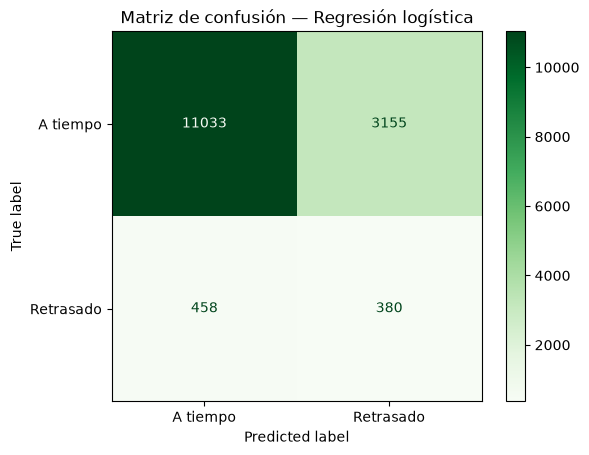

In [13]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

matriz = confusion_matrix(y_validacion, predicciones_logisticas)

ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=["A tiempo", "Retrasado"]
).plot(cmap="Greens")

plt.title("Matriz de confusión — Regresión logística")
plt.show()


### 3.3. Curva Precision–Recall

In [14]:
from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)

probabilidades = modelo_logistico.predict_proba(X_validacion)[:, 1]

precision, recall, umbrales = precision_recall_curve(
    y_validacion,
    probabilidades
)

ap = average_precision_score(y_validacion, probabilidades)

print(f"Average Precision (AP): {ap:.4f}")


Average Precision (AP): 0.0859


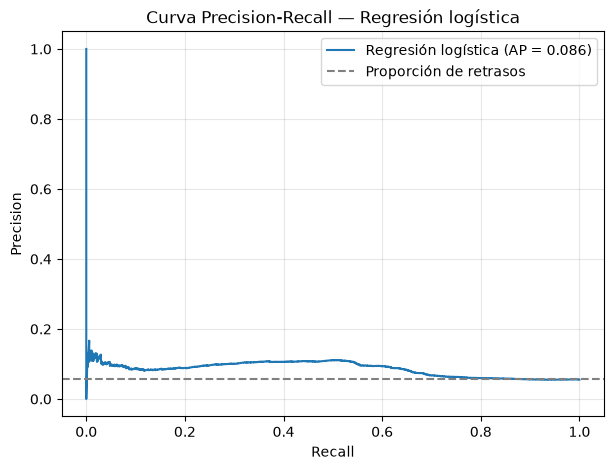

In [15]:
plt.figure(figsize=(7, 5))

plt.plot(recall, precision, label=f"Regresión logística (AP = {ap:.3f})")
plt.axhline(
    y_validacion.mean(),
    linestyle="--",
    color="gray",
    label="Proporción de retrasos"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Curva Precision-Recall — Regresión logística")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


## 4. Árbol de decisión (V1)

In [16]:
from sklearn.tree import DecisionTreeClassifier

modelo_arbol = Pipeline([
    ("preprocesamiento", preprocesamiento),
    ("clasificador", DecisionTreeClassifier(
        max_depth=5,
        min_samples_leaf=100,
        class_weight="balanced",
        random_state=42
    ))
])

modelo_arbol.fit(X_train_interno, y_train_interno)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocesamiento', ...), ('clasificador', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['customer_state','cantidad_items','peso_total_g',...,'mes_compra', 'dia_semana','hora_compra']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying 

In [17]:
predicciones_arbol = modelo_arbol.predict(X_validacion)

print(classification_report(
    y_validacion,
    predicciones_arbol,
    zero_division=0
))

probabilidades_arbol = modelo_arbol.predict_proba(X_validacion)[:, 1]

ap_arbol = average_precision_score(
    y_validacion,
    probabilidades_arbol
)

print(f"Average Precision (AP): {ap_arbol:.4f}")


              precision    recall  f1-score   support

           0       0.94      0.97      0.96     14188
           1       0.07      0.03      0.04       838

    accuracy                           0.92     15026
   macro avg       0.51      0.50      0.50     15026
weighted avg       0.90      0.92      0.91     15026

Average Precision (AP): 0.0853


### 4.1. Comparación inicial: regresión logística y árbol

In [18]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)

def evaluar_modelo(nombre, y_real, predicciones, probabilidades):
    return {
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_real, predicciones),
        "Precision": precision_score(y_real, predicciones, zero_division=0),
        "Recall": recall_score(y_real, predicciones, zero_division=0),
        "F1": f1_score(y_real, predicciones, zero_division=0),
        "AP": average_precision_score(y_real, probabilidades)
    }


resultados = pd.DataFrame([
    evaluar_modelo(
        "Regresión logística",
        y_validacion,
        predicciones_logisticas,
        probabilidades
    ),
    evaluar_modelo(
        "Árbol de decisión",
        y_validacion,
        predicciones_arbol,
        probabilidades_arbol
    )
])

resultados.round(4)


,Modelo,Accuracy,Precision,Recall,F1,AP
0,Regresión logística,0.7596,0.1075,0.4535,0.1738,0.0859
1,Árbol de decisión,0.9215,0.0660,0.0310,0.0422,0.0853


## 5. Random Forest (V1)

In [19]:
from sklearn.ensemble import RandomForestClassifier

modelo_forest = Pipeline([
    ("preprocesamiento", preprocesamiento),
    ("clasificador", RandomForestClassifier(
        n_estimators=100,
        max_depth=10,
        min_samples_leaf=20,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

modelo_forest.fit(X_train_interno, y_train_interno)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocesamiento', ...), ('clasificador', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['customer_state','cantidad_items','peso_total_g',...,'mes_compra', 'dia_semana','hora_compra']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying 

In [20]:
predicciones_forest = modelo_forest.predict(X_validacion)

probabilidades_forest = modelo_forest.predict_proba(
    X_validacion
)[:, 1]

print(classification_report(
    y_validacion,
    predicciones_forest,
    zero_division=0
))

ap_forest = average_precision_score(
    y_validacion,
    probabilidades_forest
)

print(f"Average Precision (AP): {ap_forest:.4f}")


              precision    recall  f1-score   support

           0       0.96      0.87      0.91     14188
           1       0.12      0.31      0.18       838

    accuracy                           0.84     15026
   macro avg       0.54      0.59      0.54     15026
weighted avg       0.91      0.84      0.87     15026

Average Precision (AP): 0.1029


In [21]:
resultado_forest = evaluar_modelo(
    "Random Forest",
    y_validacion,
    predicciones_forest,
    probabilidades_forest
)

resultados = pd.concat(
    [resultados, pd.DataFrame([resultado_forest])],
    ignore_index=True
)

resultados.round(4)


,Modelo,Accuracy,Precision,Recall,F1,AP
0,Regresión logística,0.7596,0.1075,0.4535,0.1738,0.0859
1,Árbol de decisión,0.9215,0.0660,0.0310,0.0422,0.0853
2,Random Forest,0.8373,0.1229,0.3126,0.1765,0.1029


### 5.1. Exploración de umbrales en los modelos iniciales

In [22]:
umbrales_prueba = [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]

resultados_umbrales = []

for umbral in umbrales_prueba:
    pred = (probabilidades_forest >= umbral).astype(int)

    resultados_umbrales.append({
        "Umbral": umbral,
        "Precision": precision_score(
            y_validacion, pred, zero_division=0
        ),
        "Recall": recall_score(
            y_validacion, pred, zero_division=0
        ),
        "F1": f1_score(
            y_validacion, pred, zero_division=0
        )
    })

tabla_umbrales = pd.DataFrame(resultados_umbrales)
tabla_umbrales.round(4)


,Umbral,Precision,Recall,F1
0,0.2,0.0559,1.0000,0.1058
1,0.3,0.0588,0.8878,0.1103
2,0.4,0.0803,0.6730,0.1434
3,0.5,0.1229,0.3126,0.1765
4,0.6,0.1591,0.0084,0.0159
5,0.7,0.1739,0.0048,0.0093


In [23]:
resultados_logisticos = []

for umbral in umbrales_prueba:
    pred = (probabilidades >= umbral).astype(int)

    resultados_logisticos.append({
        "Umbral": umbral,
        "Precision": precision_score(
            y_validacion, pred, zero_division=0
        ),
        "Recall": recall_score(
            y_validacion, pred, zero_division=0
        ),
        "F1": f1_score(
            y_validacion, pred, zero_division=0
        )
    })

tabla_umbrales_logisticos = pd.DataFrame(resultados_logisticos)

tabla_umbrales_logisticos.round(4)


,Umbral,Precision,Recall,F1
0,0.2,0.0558,0.9988,0.1057
1,0.3,0.0582,0.8473,0.1089
2,0.4,0.0943,0.5859,0.1624
3,0.5,0.1075,0.4535,0.1738
4,0.6,0.0861,0.0967,0.0911
5,0.7,0.1134,0.0131,0.0235


## 6. Validación temporal por meses

Se repiten los entrenamientos en noviembre de 2017, febrero de 2018 y abril de 2018, usando solamente etiquetas históricas conocidas antes de cada corte.

In [24]:
train["mes"] = train["order_purchase_timestamp"].dt.to_period("M")

pedidos_por_mes = train.groupby("mes").agg(
    pedidos=("retraso", "size"),
    retrasos=("retraso", "sum"),
    tasa_retraso=("retraso", "mean")
)

pedidos_por_mes.tail(12)


,pedidos,retrasos,tasa_retraso
mes,,,
2017-06,3135,95,0.030303
2017-07,3872,108,0.027893
2017-08,4193,122,0.029096
2017-09,4150,182,0.043855
2017-10,4478,187,0.041760
2017-11,7288,904,0.124040
2017-12,5513,411,0.074551
2018-01,7067,401,0.056743
2018-02,6549,920,0.140479


In [25]:
train_fechas = train.merge(
    pedidos,
    on="order_id",
    validate="one_to_one"
)

meses_validacion = pd.to_datetime([
    "2017-11-01",
    "2018-02-01",
    "2018-04-01"
])

resumen_divisiones = []

for inicio in meses_validacion:
    fin = inicio + pd.DateOffset(months=1)

    historico = train_fechas[
        (train_fechas["order_purchase_timestamp"] < inicio) &
        (train_fechas["order_delivered_customer_date"] < inicio)
    ]

    periodo = train_fechas[
        (train_fechas["order_purchase_timestamp"] >= inicio) &
        (train_fechas["order_purchase_timestamp"] < fin)
    ]

    resumen_divisiones.append({
        "Mes": inicio.strftime("%Y-%m"),
        "Entrenamiento": len(historico),
        "Validacion": len(periodo),
        "Tasa_retraso": periodo["retraso"].mean()
    })

pd.DataFrame(resumen_divisiones)


,Mes,Entrenamiento,Validacion,Tasa_retraso
0,2017-11,29322,7288,0.124040
1,2018-02,47794,6549,0.140479
2,2018-04,60468,6694,0.032417


### 6.1. Comparación temporal de modelos V1

In [26]:
from sklearn.base import clone

modelos = {
    "Regresión logística": modelo_logistico,
    "Árbol de decisión": modelo_arbol,
    "Random Forest": modelo_forest
}

resultados_temporales = []

for inicio in meses_validacion:
    fin = inicio + pd.DateOffset(months=1)

    historico = train_fechas[
        (train_fechas["order_purchase_timestamp"] < inicio) &
        (train_fechas["order_delivered_customer_date"] < inicio)
    ]

    periodo = train_fechas[
        (train_fechas["order_purchase_timestamp"] >= inicio) &
        (train_fechas["order_purchase_timestamp"] < fin)
    ]

    for nombre, modelo in modelos.items():
        estimador = clone(modelo)

        estimador.fit(
            historico[variables],
            historico["retraso"]
        )

        probabilidades_mes = estimador.predict_proba(
            periodo[variables]
        )[:, 1]

        resultados_temporales.append({
            "Mes": inicio.strftime("%Y-%m"),
            "Modelo": nombre,
            "AP": average_precision_score(
                periodo["retraso"],
                probabilidades_mes
            ),
            "Tasa_retraso": periodo["retraso"].mean()
        })

tabla_temporal = pd.DataFrame(resultados_temporales)

tabla_temporal.round(4)


,Mes,Modelo,AP,Tasa_retraso
0,2017-11,Regresión logística,0.1571,0.1240
1,2017-11,Árbol de decisión,0.1222,0.1240
2,2017-11,Random Forest,0.1152,0.1240
3,2018-02,Regresión logística,0.2434,0.1405
4,2018-02,Árbol de decisión,0.1526,0.1405
5,2018-02,Random Forest,0.2173,0.1405
6,2018-04,Regresión logística,0.0642,0.0324
7,2018-04,Árbol de decisión,0.0308,0.0324
8,2018-04,Random Forest,0.0733,0.0324


In [27]:
tabla_temporal["Mejora_relativa"] = (
    tabla_temporal["AP"] / tabla_temporal["Tasa_retraso"]
)

tabla_temporal[
    ["Mes", "Modelo", "AP", "Tasa_retraso", "Mejora_relativa"]
].round(4)


,Mes,Modelo,AP,Tasa_retraso,Mejora_relativa
0,2017-11,Regresión logística,0.1571,0.1240,1.2666
1,2017-11,Árbol de decisión,0.1222,0.1240,0.9851
2,2017-11,Random Forest,0.1152,0.1240,0.9291
3,2018-02,Regresión logística,0.2434,0.1405,1.7323
4,2018-02,Árbol de decisión,0.1526,0.1405,1.0860
5,2018-02,Random Forest,0.2173,0.1405,1.5469
6,2018-04,Regresión logística,0.0642,0.0324,1.9804
7,2018-04,Árbol de decisión,0.0308,0.0324,0.9516
8,2018-04,Random Forest,0.0733,0.0324,2.2611


## 7. XGBoost (V1)

In [28]:
from xgboost import XGBClassifier

modelo_xgboost = Pipeline([
    ("preprocesamiento", preprocesamiento),
    ("clasificador", XGBClassifier(
        n_estimators=200,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1
    ))
])

modelo_xgboost.fit(X_train_interno, y_train_interno)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocesamiento', ...), ('clasificador', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['customer_state','cantidad_items','peso_total_g',...,'mes_compra', 'dia_semana','hora_compra']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying 

In [29]:
predicciones_xgboost = modelo_xgboost.predict(X_validacion)

probabilidades_xgboost = modelo_xgboost.predict_proba(
    X_validacion
)[:, 1]

print(classification_report(
    y_validacion,
    predicciones_xgboost,
    zero_division=0
))

ap_xgboost = average_precision_score(
    y_validacion,
    probabilidades_xgboost
)

print(f"Average Precision (AP): {ap_xgboost:.4f}")


              precision    recall  f1-score   support

           0       0.94      1.00      0.97     14188
           1       0.00      0.00      0.00       838

    accuracy                           0.94     15026
   macro avg       0.47      0.50      0.49     15026
weighted avg       0.89      0.94      0.92     15026

Average Precision (AP): 0.0860


In [30]:
umbrales_xgboost = [0.05, 0.10, 0.15, 0.20, 0.30, 0.50]

resultados_xgboost = []

for umbral in umbrales_xgboost:
    pred = (probabilidades_xgboost >= umbral).astype(int)

    resultados_xgboost.append({
        "Umbral": umbral,
        "Precision": precision_score(
            y_validacion, pred, zero_division=0
        ),
        "Recall": recall_score(
            y_validacion, pred, zero_division=0
        ),
        "F1": f1_score(
            y_validacion, pred, zero_division=0
        )
    })

tabla_umbrales_xgboost = pd.DataFrame(resultados_xgboost)

tabla_umbrales_xgboost.round(4)


,Umbral,Precision,Recall,F1
0,0.05,0.0891,0.4535,0.1490
1,0.10,0.1185,0.0465,0.0668
2,0.15,0.1667,0.0107,0.0202
3,0.20,0.1538,0.0048,0.0093
4,0.30,0.2500,0.0024,0.0047
5,0.50,0.0000,0.0000,0.0000


### 7.1. XGBoost con ponderación de clases

In [31]:
conteo_clases = y_train_interno.value_counts()

peso_positivo = conteo_clases[0] / conteo_clases[1]

print(f"Peso de la clase positiva: {peso_positivo:.2f}")


Peso de la clase positiva: 18.42


In [32]:
from sklearn.base import clone

modelo_xgboost_balanceado = clone(modelo_xgboost)

modelo_xgboost_balanceado.set_params(
    clasificador__scale_pos_weight=peso_positivo
)

modelo_xgboost_balanceado.fit(
    X_train_interno,
    y_train_interno
)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocesamiento', ...), ('clasificador', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['customer_state','cantidad_items','peso_total_g',...,'mes_compra', 'dia_semana','hora_compra']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying 

In [33]:
predicciones_xgb_balanceado = modelo_xgboost_balanceado.predict(
    X_validacion
)

probabilidades_xgb_balanceado = modelo_xgboost_balanceado.predict_proba(
    X_validacion
)[:, 1]

print(classification_report(
    y_validacion,
    predicciones_xgb_balanceado,
    zero_division=0
))

ap_xgb_balanceado = average_precision_score(
    y_validacion,
    probabilidades_xgb_balanceado
)

print(f"Average Precision (AP): {ap_xgb_balanceado:.4f}")


              precision    recall  f1-score   support

           0       0.96      0.79      0.86     14188
           1       0.10      0.38      0.15       838

    accuracy                           0.77     15026
   macro avg       0.53      0.59      0.51     15026
weighted avg       0.91      0.77      0.83     15026

Average Precision (AP): 0.0852


## 8. CatBoost (V1)

In [34]:
from catboost import CatBoostClassifier

categoricas_catboost = [
    "customer_state",
    "envio_entre_estados"
]

X_train_catboost = X_train_interno.copy()
X_val_catboost = X_validacion.copy()

for columna in categoricas_catboost:
    X_train_catboost[columna] = X_train_catboost[columna].astype(str)
    X_val_catboost[columna] = X_val_catboost[columna].astype(str)


In [35]:
modelo_catboost = CatBoostClassifier(
    iterations=300,
    depth=5,
    learning_rate=0.05,
    loss_function="Logloss",
    cat_features=categoricas_catboost,
    random_seed=42,
    verbose=False,
    thread_count=-1
)

modelo_catboost.fit(
    X_train_catboost,
    y_train_interno
)


CatBoostClassifier(cat_features=['customer_state', 'envio_entre_estados'], depth=5, iterations=300, learning_rate=0.05, loss_function='Logloss', random_seed=42, verbose=False)

In [36]:
predicciones_catboost = modelo_catboost.predict(
    X_val_catboost
)

probabilidades_catboost = modelo_catboost.predict_proba(
    X_val_catboost
)[:, 1]

print(classification_report(
    y_validacion,
    predicciones_catboost,
    zero_division=0
))

ap_catboost = average_precision_score(
    y_validacion,
    probabilidades_catboost
)

print(f"Average Precision (AP): {ap_catboost:.4f}")


              precision    recall  f1-score   support

           0       0.94      1.00      0.97     14188
           1       0.00      0.00      0.00       838

    accuracy                           0.94     15026
   macro avg       0.47      0.50      0.49     15026
weighted avg       0.89      0.94      0.92     15026

Average Precision (AP): 0.0957


### 8.1. Evaluación de umbrales de CatBoost

In [37]:
umbrales_catboost = [0.05, 0.10, 0.15, 0.20, 0.30, 0.50]

resultados_catboost = []

for umbral in umbrales_catboost:
    pred = (probabilidades_catboost >= umbral).astype(int)

    resultados_catboost.append({
        "Umbral": umbral,
        "Precision": precision_score(
            y_validacion, pred, zero_division=0
        ),
        "Recall": recall_score(
            y_validacion, pred, zero_division=0
        ),
        "F1": f1_score(
            y_validacion, pred, zero_division=0
        )
    })

tabla_umbrales_catboost = pd.DataFrame(resultados_catboost)

tabla_umbrales_catboost.round(4)


,Umbral,Precision,Recall,F1
0,0.05,0.1128,0.4224,0.1781
1,0.10,0.1381,0.0394,0.0613
2,0.15,0.2041,0.0119,0.0225
3,0.20,0.1538,0.0048,0.0093
4,0.30,0.1818,0.0024,0.0047
5,0.50,0.0000,0.0000,0.0000


### 8.2. Validación temporal de XGBoost y CatBoost

In [38]:
resultados_avanzados = []

for inicio in meses_validacion:
    fin = inicio + pd.DateOffset(months=1)

    historico = train_fechas[
        (train_fechas["order_purchase_timestamp"] < inicio) &
        (train_fechas["order_delivered_customer_date"] < inicio)
    ]

    periodo = train_fechas[
        (train_fechas["order_purchase_timestamp"] >= inicio) &
        (train_fechas["order_purchase_timestamp"] < fin)
    ]

    # XGBoost
    xgb = clone(modelo_xgboost)
    xgb.fit(historico[variables], historico["retraso"])

    prob_xgb = xgb.predict_proba(periodo[variables])[:, 1]

    resultados_avanzados.append({
        "Mes": inicio.strftime("%Y-%m"),
        "Modelo": "XGBoost",
        "AP": average_precision_score(periodo["retraso"], prob_xgb),
        "Tasa_retraso": periodo["retraso"].mean()
    })

    # CatBoost
    X_hist = historico[variables].copy()
    X_periodo = periodo[variables].copy()

    for columna in categoricas_catboost:
        X_hist[columna] = X_hist[columna].astype(str)
        X_periodo[columna] = X_periodo[columna].astype(str)

    cat = CatBoostClassifier(
        iterations=300,
        depth=5,
        learning_rate=0.05,
        loss_function="Logloss",
        cat_features=categoricas_catboost,
        random_seed=42,
        verbose=False,
        thread_count=-1
    )

    cat.fit(X_hist, historico["retraso"])

    prob_cat = cat.predict_proba(X_periodo)[:, 1]

    resultados_avanzados.append({
        "Mes": inicio.strftime("%Y-%m"),
        "Modelo": "CatBoost",
        "AP": average_precision_score(periodo["retraso"], prob_cat),
        "Tasa_retraso": periodo["retraso"].mean()
    })

tabla_avanzados = pd.DataFrame(resultados_avanzados)
tabla_avanzados["Mejora_relativa"] = (
    tabla_avanzados["AP"] / tabla_avanzados["Tasa_retraso"]
)

tabla_avanzados.round(4)


,Mes,Modelo,AP,Tasa_retraso,Mejora_relativa
0,2017-11,XGBoost,0.1210,0.1240,0.9753
1,2017-11,CatBoost,0.1143,0.1240,0.9213
2,2018-02,XGBoost,0.2099,0.1405,1.4943
3,2018-02,CatBoost,0.2097,0.1405,1.4931
4,2018-04,XGBoost,0.0714,0.0324,2.2026
5,2018-04,CatBoost,0.0873,0.0324,2.6926


## 9. Comparación de modelos V1

In [39]:
comparacion_general = pd.concat(
    [tabla_temporal, tabla_avanzados],
    ignore_index=True
)

resumen_modelos = (
    comparacion_general
    .groupby("Modelo")
    .agg(
        AP_promedio=("AP", "mean"),
        Mejora_promedio=("Mejora_relativa", "mean"),
        Mejora_minima=("Mejora_relativa", "min")
    )
    .sort_values("Mejora_promedio", ascending=False)
)

resumen_modelos.round(4)


,AP_promedio,Mejora_promedio,Mejora_minima
Modelo,,,
CatBoost,0.1371,1.7023,0.9213
Regresión logística,0.1549,1.6598,1.2666
Random Forest,0.1353,1.5791,0.9291
XGBoost,0.1341,1.5574,0.9753
Árbol de decisión,0.1019,1.0076,0.9516


### 9.1. Comparación de candidatos iniciales

In [40]:
finalistas = comparacion_general[
    comparacion_general["Modelo"].isin([
        "Regresión logística",
        "CatBoost"
    ])
]

comparacion_finalistas = finalistas.pivot(
    index="Mes",
    columns="Modelo",
    values="Mejora_relativa"
)

comparacion_finalistas.round(4)


Modelo,CatBoost,Regresión logística
Mes,,
2017-11,0.9213,1.2666
2018-02,1.4931,1.7323
2018-04,2.6926,1.9804


## 10. Evaluación final original: V1

La evaluación de `test.csv` pertenece exclusivamente a la versión inicial de ocho características. Su resultado se conserva por transparencia; **no es una prueba independiente de V2 ni V3**.

In [41]:
X_train_final = train[variables]
y_train_final = train["retraso"]

X_test_final = test[variables]
y_test_final = test["retraso"]

print("Entrenamiento:", X_train_final.shape)
print("Prueba:", X_test_final.shape)
print("Retrasos en entrenamiento:", y_train_final.mean().round(4))


Entrenamiento: (75128, 8)
Prueba: (19294, 8)
Retrasos en entrenamiento: 0.0711


In [42]:
from sklearn.base import clone

modelo_final = clone(modelo_logistico)

modelo_final.fit(X_train_final, y_train_final)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocesamiento', ...), ('clasificador', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](8,)","['customer_state','cantidad_items','peso_total_g',...,'mes_compra', 'dia_semana','hora_compra']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying 

In [43]:
predicciones_finales = modelo_final.predict(X_test_final)

probabilidades_finales = modelo_final.predict_proba(
    X_test_final
)[:, 1]

print(classification_report(
    y_test_final,
    predicciones_finales,
    zero_division=0
))


              precision    recall  f1-score   support

           0       0.97      0.71      0.82     18620
           1       0.04      0.29      0.06       674

    accuracy                           0.69     19294
   macro avg       0.50      0.50      0.44     19294
weighted avg       0.93      0.69      0.79     19294



In [44]:
ap_final = average_precision_score(
    y_test_final,
    probabilidades_finales
)

print(f"Average Precision final: {ap_final:.4f}")
print(f"Referencia: {y_test_final.mean():.4f}")


Average Precision final: 0.0336
Referencia: 0.0349


### 10.1. Matriz de confusión de la prueba original

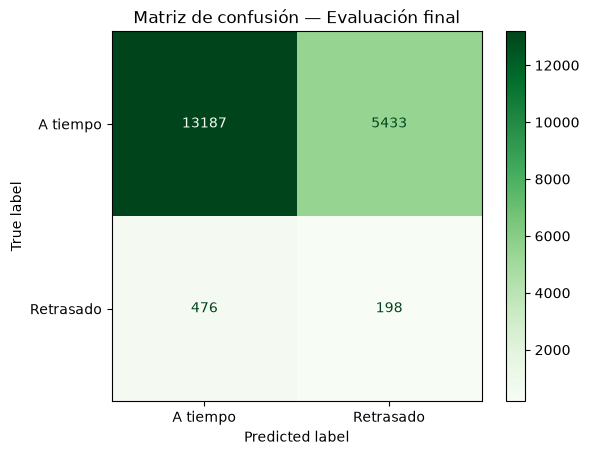

In [45]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test_final,
    predicciones_finales,
    display_labels=["A tiempo", "Retrasado"],
    cmap="Greens",
    values_format="d"
)

plt.title("Matriz de confusión — Evaluación final")
plt.show()


## 11. Experimento V2: días prometidos

Se añade `dias_prometidos` al entrenamiento histórico sin sobrescribir los archivos de la versión inicial.

In [46]:
train_v2 = pd.read_csv(
    "../data/processed/train_v2.csv",
    parse_dates=["order_purchase_timestamp"]
)

variables_v2 = variables + ["dias_prometidos"]

print("Dimensiones:", train_v2.shape)
print("Variables V2:", len(variables_v2))
print("Valores faltantes:", train_v2["dias_prometidos"].isna().sum())


Dimensiones: (75128, 12)
Variables V2: 9
Valores faltantes: 0


### 11.1. Regresión logística y comparación temporal V1–V2

In [47]:
from sklearn.base import clone

preprocesamiento_v2 = clone(preprocesamiento)

numericas_v2 = numericas + ["dias_prometidos"]

preprocesamiento_v2.set_params(
    transformers=[
        ("num", Pipeline([
            ("imputador", SimpleImputer(strategy="median")),
            ("escalador", StandardScaler())
        ]), numericas_v2),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categoricas)
    ]
)

modelo_logistico_v2 = Pipeline([
    ("preprocesamiento", preprocesamiento_v2),
    ("clasificador", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

modelo_logistico_v2


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocesamiento', ...), ('clasificador', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, defaul

### 11.2. Preparación de las fechas para validar V2

In [48]:
train_v2_fechas = train_v2.merge(
    pedidos,
    on="order_id",
    validate="one_to_one"
)

train_v2_fechas.shape


(75128, 13)

In [49]:
resultados_v1_v2 = []

for inicio in meses_validacion:
    fin = inicio + pd.DateOffset(months=1)

    historico = train_v2_fechas[
        (train_v2_fechas["order_purchase_timestamp"] < inicio) &
        (train_v2_fechas["order_delivered_customer_date"] < inicio)
    ]

    periodo = train_v2_fechas[
        (train_v2_fechas["order_purchase_timestamp"] >= inicio) &
        (train_v2_fechas["order_purchase_timestamp"] < fin)
    ]

    for version, modelo, columnas in [
        ("V1", modelo_logistico, variables),
        ("V2", modelo_logistico_v2, variables_v2)
    ]:
        estimador = clone(modelo)

        estimador.fit(
            historico[columnas],
            historico["retraso"]
        )

        probabilidades_mes = estimador.predict_proba(
            periodo[columnas]
        )[:, 1]

        resultados_v1_v2.append({
            "Mes": inicio.strftime("%Y-%m"),
            "Version": version,
            "AP": average_precision_score(
                periodo["retraso"],
                probabilidades_mes
            )
        })

tabla_v1_v2 = pd.DataFrame(resultados_v1_v2)

tabla_v1_v2


,Mes,Version,AP
0,2017-11,V1,0.157114
1,2017-11,V2,0.163774
2,2018-02,V1,0.243356
3,2018-02,V2,0.276886
4,2018-04,V1,0.064197
5,2018-04,V2,0.132365


### 11.3. AP relativa a la tasa de retrasos

In [50]:
tasas_mensuales = (
    tabla_temporal[["Mes", "Tasa_retraso"]]
    .drop_duplicates()
)

comparacion_v2 = tabla_v1_v2.merge(
    tasas_mensuales,
    on="Mes",
    validate="many_to_one"
)

comparacion_v2["Mejora_relativa"] = (
    comparacion_v2["AP"] /
    comparacion_v2["Tasa_retraso"]
)

comparacion_v2.round(4)


,Mes,Version,AP,Tasa_retraso,Mejora_relativa
0,2017-11,V1,0.1571,0.1240,1.2666
1,2017-11,V2,0.1638,0.1240,1.3203
2,2018-02,V1,0.2434,0.1405,1.7323
3,2018-02,V2,0.2769,0.1405,1.9710
4,2018-04,V1,0.0642,0.0324,1.9804
5,2018-04,V2,0.1324,0.0324,4.0832


## 12. Experimento V3: distancia logística

Se añade `distancia_maxima_km`, calculada previamente por pedido. Las distancias faltantes permanecen como valores nulos y se imputan dentro del pipeline.

In [51]:
train_v3 = pd.read_csv(
    "../data/processed/train_v3.csv",
    parse_dates=["order_purchase_timestamp"]
)

variables_v3 = variables_v2 + ["distancia_maxima_km"]

print("Dimensiones V3:", train_v3.shape)
print("Variables predictoras:", len(variables_v3))

print(
    "Distancias faltantes:",
    train_v3["distancia_maxima_km"].isna().sum()
)

print(
    "Pedidos duplicados:",
    train_v3["order_id"].duplicated().sum()
)


Dimensiones V3: (75128, 13)
Variables predictoras: 10
Distancias faltantes: 390
Pedidos duplicados: 0


### 12.1. Modelo V3 y su preprocesamiento

In [52]:
from sklearn.base import clone

preprocesamiento_v3 = clone(preprocesamiento_v2)

preprocesamiento_v3.set_params(
    transformers=[
        (
            "num",
            Pipeline([
                ("imputador", SimpleImputer(strategy="median")),
                ("escalador", StandardScaler())
            ]),
            numericas_v2 + ["distancia_maxima_km"]
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categoricas
        )
    ]
)

modelo_logistico_v3 = Pipeline([
    ("preprocesamiento", preprocesamiento_v3),
    ("clasificador", LogisticRegression(
        class_weight="balanced",
        max_iter=1000,
        random_state=42
    ))
])

modelo_logistico_v3


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocesamiento', ...), ('clasificador', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, defaul

### 12.2. Validación temporal V2–V3

In [53]:
train_v3_fechas = train_v3.merge(
    pedidos,
    on="order_id",
    validate="one_to_one"
)

print("Dimensiones:", train_v3_fechas.shape)
print("Distancias faltantes:",
      train_v3_fechas["distancia_maxima_km"].isna().sum())


Dimensiones: (75128, 14)
Distancias faltantes: 390


In [54]:
resultados_v2_v3 = []

for inicio in meses_validacion:
    fin = inicio + pd.DateOffset(months=1)

    historico = train_v3_fechas[
        (train_v3_fechas["order_purchase_timestamp"] < inicio) &
        (train_v3_fechas["order_delivered_customer_date"] < inicio)
    ]

    periodo = train_v3_fechas[
        (train_v3_fechas["order_purchase_timestamp"] >= inicio) &
        (train_v3_fechas["order_purchase_timestamp"] < fin)
    ]

    for version, modelo, columnas in [
        ("V2", modelo_logistico_v2, variables_v2),
        ("V3", modelo_logistico_v3, variables_v3)
    ]:
        estimador = clone(modelo)

        estimador.fit(
            historico[columnas],
            historico["retraso"]
        )

        probabilidades = estimador.predict_proba(
            periodo[columnas]
        )[:, 1]

        resultados_v2_v3.append({
            "Mes": inicio.strftime("%Y-%m"),
            "Version": version,
            "AP": average_precision_score(
                periodo["retraso"],
                probabilidades
            )
        })

tabla_v2_v3 = pd.DataFrame(resultados_v2_v3)

tabla_v2_v3.round(4)


,Mes,Version,AP
0,2017-11,V2,0.1638
1,2017-11,V3,0.1659
2,2018-02,V2,0.2769
3,2018-02,V3,0.2795
4,2018-04,V2,0.1324
5,2018-04,V3,0.1379


### 12.3. Comparación conjunta V1–V3

In [55]:
comparacion_final = pd.concat(
    [
        tabla_v1_v2,
        tabla_v2_v3[tabla_v2_v3["Version"] == "V3"]
    ],
    ignore_index=True
)

resumen_versiones = comparacion_final.pivot(
    index="Mes",
    columns="Version",
    values="AP"
)

resumen_versiones["Mejora_V2_%"] = (
    (resumen_versiones["V2"] / resumen_versiones["V1"] - 1) * 100
)

resumen_versiones["Mejora_V3_%"] = (
    (resumen_versiones["V3"] / resumen_versiones["V1"] - 1) * 100
)

resumen_versiones.round(4)


Version,V1,V2,V3,Mejora_V2_%,Mejora_V3_%
Mes,,,,,
2017-11,0.1571,0.1638,0.1659,4.2391,5.6107
2018-02,0.2434,0.2769,0.2795,13.7780,14.8677
2018-04,0.0642,0.1324,0.1379,106.1838,114.8788


## 13. Alertas y comportamiento temporal de V3

Se examina el desempeño con distintos umbrales. Los resultados son exploratorios y no definen por sí solos un umbral óptimo.

In [56]:
from sklearn.metrics import classification_report, confusion_matrix

inicio = pd.Timestamp("2018-04-01")
fin = pd.Timestamp("2018-05-01")

historico = train_v3_fechas[
    (train_v3_fechas["order_purchase_timestamp"] < inicio)
    & (train_v3_fechas["order_delivered_customer_date"] < inicio)
]

validacion = train_v3_fechas[
    (train_v3_fechas["order_purchase_timestamp"] >= inicio)
    & (train_v3_fechas["order_purchase_timestamp"] < fin)
]

modelo_evaluacion_v3 = clone(modelo_logistico_v3)

modelo_evaluacion_v3.fit(
    historico[variables_v3],
    historico["retraso"]
)

predicciones_v3 = modelo_evaluacion_v3.predict(
    validacion[variables_v3]
)

print("Matriz de confusión:")
print(confusion_matrix(validacion["retraso"], predicciones_v3))

print("\nReporte de clasificación:")
print(classification_report(
    validacion["retraso"],
    predicciones_v3,
    zero_division=0
))


Matriz de confusión:
[[4721 1756]
 [  58  159]]

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.99      0.73      0.84      6477
           1       0.08      0.73      0.15       217

    accuracy                           0.73      6694
   macro avg       0.54      0.73      0.49      6694
weighted avg       0.96      0.73      0.82      6694



### 13.1. Comparación de umbrales en abril de 2018

In [57]:
from sklearn.metrics import precision_score, recall_score, f1_score

probabilidades_v3 = modelo_evaluacion_v3.predict_proba(
    validacion[variables_v3]
)[:, 1]

resultados_umbrales = []

for umbral in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    predicciones = (probabilidades_v3 >= umbral).astype(int)

    resultados_umbrales.append({
        "Umbral": umbral,
        "Alertas": int(predicciones.sum()),
        "Precision": precision_score(
            validacion["retraso"], predicciones, zero_division=0
        ),
        "Recall": recall_score(
            validacion["retraso"], predicciones, zero_division=0
        ),
        "F1": f1_score(
            validacion["retraso"], predicciones, zero_division=0
        )
    })

tabla_umbrales = pd.DataFrame(resultados_umbrales)

tabla_umbrales.round(4)


,Umbral,Alertas,Precision,Recall,F1
0,0.3,6174,0.0348,0.9908,0.0673
1,0.4,4009,0.0491,0.9078,0.0932
2,0.5,1915,0.0830,0.7327,0.1492
3,0.6,987,0.1206,0.5484,0.1977
4,0.7,293,0.1843,0.2488,0.2118
5,0.8,42,0.2857,0.0553,0.0927


In [58]:
umbral = 0.7

predicciones_07 = (
    probabilidades_v3 >= umbral
).astype(int)

print("Matriz de confusión:")
print(confusion_matrix(
    validacion["retraso"],
    predicciones_07
))

print("\nReporte de clasificación:")
print(classification_report(
    validacion["retraso"],
    predicciones_07,
    zero_division=0
))


Matriz de confusión:
[[6238  239]
 [ 163   54]]

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.97      0.96      0.97      6477
           1       0.18      0.25      0.21       217

    accuracy                           0.94      6694
   macro avg       0.58      0.61      0.59      6694
weighted avg       0.95      0.94      0.94      6694



### 13.2. Estabilidad de umbrales entre meses

In [59]:
resultados_estabilidad = []

for inicio in meses_validacion:
    fin = inicio + pd.DateOffset(months=1)

    historico = train_v3_fechas[
        (train_v3_fechas["order_purchase_timestamp"] < inicio)
        & (train_v3_fechas["order_delivered_customer_date"] < inicio)
    ]

    periodo = train_v3_fechas[
        (train_v3_fechas["order_purchase_timestamp"] >= inicio)
        & (train_v3_fechas["order_purchase_timestamp"] < fin)
    ]

    modelo = clone(modelo_logistico_v3)
    modelo.fit(historico[variables_v3], historico["retraso"])

    probabilidades = modelo.predict_proba(periodo[variables_v3])[:, 1]

    for umbral in [0.5, 0.7]:
        predicciones = (probabilidades >= umbral).astype(int)

        resultados_estabilidad.append({
            "Mes": inicio.strftime("%Y-%m"),
            "Umbral": umbral,
            "Alertas": int(predicciones.sum()),
            "Precision": precision_score(
                periodo["retraso"], predicciones, zero_division=0
            ),
            "Recall": recall_score(
                periodo["retraso"], predicciones, zero_division=0
            ),
            "F1": f1_score(
                periodo["retraso"], predicciones, zero_division=0
            )
        })

tabla_estabilidad = pd.DataFrame(resultados_estabilidad)

tabla_estabilidad.round(4)


,Mes,Umbral,Alertas,Precision,Recall,F1
0,2017-11,0.5,526,0.1901,0.1106,0.1399
1,2017-11,0.7,87,0.2069,0.0199,0.0363
2,2018-02,0.5,322,0.3323,0.1163,0.1723
3,2018-02,0.7,26,0.5000,0.0141,0.0275
4,2018-04,0.5,1915,0.0830,0.7327,0.1492
5,2018-04,0.7,293,0.1843,0.2488,0.2118


### 13.3. Distribución de puntuaciones por período

In [60]:
import numpy as np
resultados_puntuaciones = []

for inicio in meses_validacion:
    fin = inicio + pd.DateOffset(months=1)

    historico = train_v3_fechas[
        (train_v3_fechas["order_purchase_timestamp"] < inicio)
        & (train_v3_fechas["order_delivered_customer_date"] < inicio)
    ]

    periodo = train_v3_fechas[
        (train_v3_fechas["order_purchase_timestamp"] >= inicio)
        & (train_v3_fechas["order_purchase_timestamp"] < fin)
    ]

    modelo = clone(modelo_logistico_v3)
    modelo.fit(historico[variables_v3], historico["retraso"])

    probabilidades = modelo.predict_proba(
        periodo[variables_v3]
    )[:, 1]

    resultados_puntuaciones.append({
        "Mes": inicio.strftime("%Y-%m"),
        "Tasa_retraso": periodo["retraso"].mean(),
        "Puntuacion_media": probabilidades.mean(),
        "Mediana": np.median(probabilidades),
        "Percentil_90": np.percentile(probabilidades, 90)
    })

tabla_puntuaciones = pd.DataFrame(resultados_puntuaciones)

tabla_puntuaciones.round(4)


,Mes,Tasa_retraso,Puntuacion_media,Mediana,Percentil_90
0,2017-11,0.1240,0.2974,0.2855,0.4560
1,2018-02,0.1405,0.2808,0.2497,0.4626
2,2018-04,0.0324,0.4494,0.4247,0.6413


### 13.4. Puntuaciones por clase real

In [61]:
resultados_clases = []

for inicio in meses_validacion:
    fin = inicio + pd.DateOffset(months=1)

    historico = train_v3_fechas[
        (train_v3_fechas["order_purchase_timestamp"] < inicio)
        & (train_v3_fechas["order_delivered_customer_date"] < inicio)
    ]

    periodo = train_v3_fechas[
        (train_v3_fechas["order_purchase_timestamp"] >= inicio)
        & (train_v3_fechas["order_purchase_timestamp"] < fin)
    ].copy()

    modelo = clone(modelo_logistico_v3)
    modelo.fit(historico[variables_v3], historico["retraso"])

    periodo["puntuacion"] = modelo.predict_proba(
        periodo[variables_v3]
    )[:, 1]

    resumen = periodo.groupby("retraso")["puntuacion"].mean()

    resultados_clases.append({
        "Mes": inicio.strftime("%Y-%m"),
        "Puntuales": resumen.get(0, np.nan),
        "Retrasados": resumen.get(1, np.nan)
    })

tabla_clases = pd.DataFrame(resultados_clases)

tabla_clases.round(4)


,Mes,Puntuales,Retrasados
0,2017-11,0.2917,0.3380
1,2018-02,0.2682,0.3577
2,2018-04,0.4444,0.5973


### 13.5. ROC-AUC por mes

In [62]:
from sklearn.metrics import roc_auc_score

resultados_auc = []

for inicio in meses_validacion:
    fin = inicio + pd.DateOffset(months=1)

    historico = train_v3_fechas[
        (train_v3_fechas["order_purchase_timestamp"] < inicio)
        & (train_v3_fechas["order_delivered_customer_date"] < inicio)
    ]

    periodo = train_v3_fechas[
        (train_v3_fechas["order_purchase_timestamp"] >= inicio)
        & (train_v3_fechas["order_purchase_timestamp"] < fin)
    ]

    modelo = clone(modelo_logistico_v3)
    modelo.fit(historico[variables_v3], historico["retraso"])

    puntuaciones = modelo.predict_proba(
        periodo[variables_v3]
    )[:, 1]

    resultados_auc.append({
        "Mes": inicio.strftime("%Y-%m"),
        "ROC_AUC": roc_auc_score(
            periodo["retraso"],
            puntuaciones
        )
    })

tabla_auc = pd.DataFrame(resultados_auc)

tabla_auc.round(4)


,Mes,ROC_AUC
0,2017-11,0.6067
1,2018-02,0.6912
2,2018-04,0.7976


## 14. Diagnóstico y experimento de calibración

Primero se describe la descalibración de V3 en abril. Luego se entrena un calibrador con febrero y se examina en abril. La mejora frente al modelo original no implica automáticamente superar una referencia de probabilidad constante.

In [63]:
from sklearn.calibration import calibration_curve

fraccion_positivos, probabilidad_media = calibration_curve(
    validacion["retraso"],
    probabilidades_v3,
    n_bins=5,
    strategy="quantile"
)

tabla_calibracion = pd.DataFrame({
    "Puntuacion_media": probabilidad_media,
    "Frecuencia_real_retraso": fraccion_positivos
})

tabla_calibracion.round(4)


,Puntuacion_media,Frecuencia_real_retraso
0,0.3019,0.0045
1,0.3722,0.0105
2,0.4255,0.0142
3,0.4967,0.0373
4,0.6507,0.0956


### 14.1. Curva de calibración observada

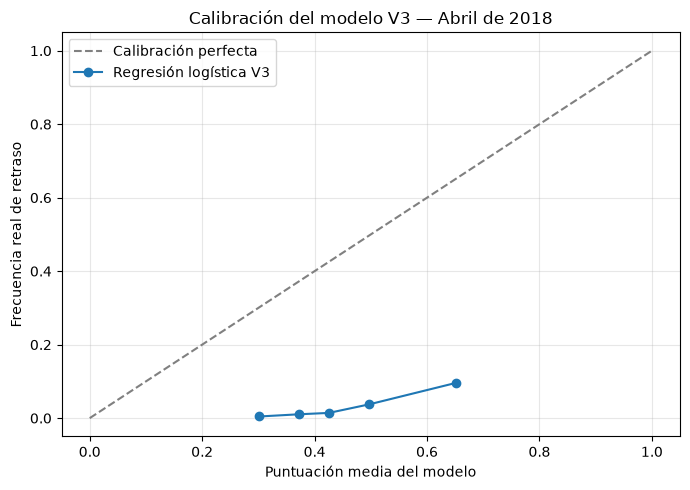

In [64]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.plot(
    [0, 1], [0, 1],
    "--",
    color="gray",
    label="Calibración perfecta"
)

plt.plot(
    tabla_calibracion["Puntuacion_media"],
    tabla_calibracion["Frecuencia_real_retraso"],
    marker="o",
    label="Regresión logística V3"
)

plt.xlabel("Puntuación media del modelo")
plt.ylabel("Frecuencia real de retraso")
plt.title("Calibración del modelo V3 — Abril de 2018")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### 14.2. Separación temporal para calibrar

In [65]:
inicio_calibracion = pd.Timestamp("2018-02-01")
fin_calibracion = pd.Timestamp("2018-03-01")
inicio_evaluacion = pd.Timestamp("2018-04-01")

datos_entrenamiento = train_v3_fechas[
    (train_v3_fechas["order_purchase_timestamp"] < inicio_calibracion)
    & (train_v3_fechas["order_delivered_customer_date"] < inicio_calibracion)
].copy()

datos_calibracion = train_v3_fechas[
    (train_v3_fechas["order_purchase_timestamp"] >= inicio_calibracion)
    & (train_v3_fechas["order_purchase_timestamp"] < fin_calibracion)
    & (train_v3_fechas["order_delivered_customer_date"] < inicio_evaluacion)
].copy()

datos_evaluacion = train_v3_fechas[
    (train_v3_fechas["order_purchase_timestamp"] >= inicio_evaluacion)
    & (train_v3_fechas["order_purchase_timestamp"] < pd.Timestamp("2018-05-01"))
].copy()

print("Entrenamiento:", datos_entrenamiento.shape)
print("Calibración:", datos_calibracion.shape)
print("Evaluación:", datos_evaluacion.shape)

print("\nTasas de retraso:")
print("Entrenamiento:", round(datos_entrenamiento["retraso"].mean(), 4))
print("Calibración:", round(datos_calibracion["retraso"].mean(), 4))
print("Evaluación:", round(datos_evaluacion["retraso"].mean(), 4))


Entrenamiento: (47794, 14)
Calibración: (6231, 14)
Evaluación: (6694, 14)

Tasas de retraso:
Entrenamiento: 0.0499
Calibración: 0.0979
Evaluación: 0.0324


### 14.3. Puntuaciones del modelo base

In [66]:
# Entrenar V3 con los datos históricos
modelo_base_calibracion = clone(modelo_logistico_v3)

modelo_base_calibracion.fit(
    datos_entrenamiento[variables_v3],
    datos_entrenamiento["retraso"]
)

# Obtener puntuaciones para calibrar
scores_calibracion = modelo_base_calibracion.predict_proba(
    datos_calibracion[variables_v3]
)[:, 1]

# Obtener puntuaciones para evaluar
scores_evaluacion = modelo_base_calibracion.predict_proba(
    datos_evaluacion[variables_v3]
)[:, 1]

print("Puntuaciones de calibración:", len(scores_calibracion))
print("Puntuaciones de evaluación:", len(scores_evaluacion))

print(
    "Puntuación media en calibración:",
    round(scores_calibracion.mean(), 4)
)

print(
    "Puntuación media en evaluación:",
    round(scores_evaluacion.mean(), 4)
)


Puntuaciones de calibración: 6231
Puntuaciones de evaluación: 6694
Puntuación media en calibración: 0.2756
Puntuación media en evaluación: 0.3309


### 14.4. Calibración sigmoide experimental

In [67]:
# Calibración sigmoide de las puntuaciones
calibrador = LogisticRegression()

calibrador.fit(
    scores_calibracion.reshape(-1, 1),
    datos_calibracion["retraso"]
)

# Transformar las puntuaciones
probabilidades_calibradas = calibrador.predict_proba(
    scores_evaluacion.reshape(-1, 1)
)[:, 1]

print(
    "Puntuación media original:",
    round(scores_evaluacion.mean(), 4)
)

print(
    "Probabilidad media calibrada:",
    round(probabilidades_calibradas.mean(), 4)
)

print(
    "Tasa real de retrasos:",
    round(datos_evaluacion["retraso"].mean(), 4)
)


Puntuación media original: 0.3309
Probabilidad media calibrada: 0.1208
Tasa real de retrasos: 0.0324


### 14.5. Brier Score, Log Loss y discriminación

In [68]:
from sklearn.metrics import brier_score_loss, log_loss

y_real = datos_evaluacion["retraso"]

comparacion_calibracion = pd.DataFrame({
    "Modelo": ["V3 original", "V3 calibrado"],
    "Brier_Score": [
        brier_score_loss(y_real, scores_evaluacion),
        brier_score_loss(y_real, probabilidades_calibradas)
    ],
    "Log_Loss": [
        log_loss(y_real, scores_evaluacion),
        log_loss(y_real, probabilidades_calibradas)
    ],
    "ROC_AUC": [
        roc_auc_score(y_real, scores_evaluacion),
        roc_auc_score(y_real, probabilidades_calibradas)
    ],
    "Average_Precision": [
        average_precision_score(y_real, scores_evaluacion),
        average_precision_score(y_real, probabilidades_calibradas)
    ]
})

comparacion_calibracion.round(4)


,Modelo,Brier_Score,Log_Loss,ROC_AUC,Average_Precision
0,V3 original,0.1251,0.4248,0.7879,0.1376
1,V3 calibrado,0.0379,0.1793,0.7879,0.1376


### 14.6. Comparación con una referencia constante

In [69]:
probabilidad_referencia = datos_calibracion["retraso"].mean()

referencia = np.full(
    len(datos_evaluacion),
    probabilidad_referencia
)

print(
    "Probabilidad de referencia:",
    round(probabilidad_referencia, 4)
)

print(
    "Brier Score referencia:",
    round(brier_score_loss(y_real, referencia), 4)
)

print(
    "Brier Score V3 calibrado:",
    round(brier_score_loss(y_real, probabilidades_calibradas), 4)
)


Probabilidad de referencia: 0.0979
Brier Score referencia: 0.0357
Brier Score V3 calibrado: 0.0379


## 15. Priorización de pedidos por riesgo

Se revisa el 10 % de pedidos con puntuaciones más altas. Esto evalúa una posible estrategia de seguimiento operativo, distinta de estimar probabilidades perfectamente calibradas.

In [70]:
evaluacion_riesgo = datos_evaluacion[
    ["order_id", "retraso"]
].copy()

evaluacion_riesgo["puntuacion"] = scores_evaluacion

evaluacion_riesgo = evaluacion_riesgo.sort_values(
    "puntuacion",
    ascending=False
)

k = int(np.ceil(len(evaluacion_riesgo) * 0.10))

top_10 = evaluacion_riesgo.head(k)

precision_top10 = top_10["retraso"].mean()

recall_top10 = (
    top_10["retraso"].sum()
    / evaluacion_riesgo["retraso"].sum()
)

print("Pedidos evaluados:", len(evaluacion_riesgo))
print("Pedidos seleccionados:", len(top_10))
print("Retrasos encontrados:", top_10["retraso"].sum())
print(f"Precision@10%: {precision_top10:.4f}")
print(f"Recall@10%: {recall_top10:.4f}")
print(f"Tasa general de retrasos: {evaluacion_riesgo['retraso'].mean():.4f}")


Pedidos evaluados: 6694
Pedidos seleccionados: 670
Retrasos encontrados: 105
Precision@10%: 0.1567
Recall@10%: 0.4839
Tasa general de retrasos: 0.0324


### 15.1. Resultados en las tres ventanas temporales

In [71]:
resultados_top10 = []

for inicio in meses_validacion:
    fin = inicio + pd.DateOffset(months=1)

    historico = train_v3_fechas[
        (train_v3_fechas["order_purchase_timestamp"] < inicio)
        & (train_v3_fechas["order_delivered_customer_date"] < inicio)
    ]

    periodo = train_v3_fechas[
        (train_v3_fechas["order_purchase_timestamp"] >= inicio)
        & (train_v3_fechas["order_purchase_timestamp"] < fin)
    ].copy()

    modelo = clone(modelo_logistico_v3)
    modelo.fit(
        historico[variables_v3],
        historico["retraso"]
    )

    periodo["puntuacion"] = modelo.predict_proba(
        periodo[variables_v3]
    )[:, 1]

    periodo = periodo.sort_values(
        "puntuacion",
        ascending=False
    )

    k = int(np.ceil(len(periodo) * 0.10))
    seleccionados = periodo.head(k)

    precision = seleccionados["retraso"].mean()
    recall = (
        seleccionados["retraso"].sum()
        / periodo["retraso"].sum()
    )

    resultados_top10.append({
        "Mes": inicio.strftime("%Y-%m"),
        "Pedidos_seleccionados": k,
        "Retrasos_encontrados": int(seleccionados["retraso"].sum()),
        "Precision_10": precision,
        "Recall_10": recall,
        "Lift": precision / periodo["retraso"].mean()
    })

tabla_top10 = pd.DataFrame(resultados_top10)

tabla_top10.round(4)


,Mes,Pedidos_seleccionados,Retrasos_encontrados,Precision_10,Recall_10,Lift
0,2017-11,729,143,0.1962,0.1582,1.5814
1,2018-02,655,241,0.3679,0.2620,2.6192
2,2018-04,670,99,0.1478,0.4562,4.5581


### 15.2. Comparación de priorización V1–V3

In [72]:
resultados_comparacion_top10 = []

for inicio in meses_validacion:
    fin = inicio + pd.DateOffset(months=1)

    historico = train_v3_fechas[
        (train_v3_fechas["order_purchase_timestamp"] < inicio)
        & (train_v3_fechas["order_delivered_customer_date"] < inicio)
    ]

    periodo = train_v3_fechas[
        (train_v3_fechas["order_purchase_timestamp"] >= inicio)
        & (train_v3_fechas["order_purchase_timestamp"] < fin)
    ]

    for version, modelo, columnas in [
        ("V1", modelo_logistico, variables),
        ("V2", modelo_logistico_v2, variables_v2),
        ("V3", modelo_logistico_v3, variables_v3)
    ]:
        estimador = clone(modelo)

        estimador.fit(
            historico[columnas],
            historico["retraso"]
        )

        puntuaciones = estimador.predict_proba(
            periodo[columnas]
        )[:, 1]

        k = int(np.ceil(len(periodo) * 0.10))
        indices_top = np.argsort(puntuaciones)[-k:]

        retrasos_top = periodo["retraso"].iloc[indices_top].sum()

        resultados_comparacion_top10.append({
            "Mes": inicio.strftime("%Y-%m"),
            "Version": version,
            "Precision_10": retrasos_top / k,
            "Recall_10": retrasos_top / periodo["retraso"].sum(),
            "Retrasos_encontrados": int(retrasos_top)
        })

tabla_comparacion_top10 = pd.DataFrame(
    resultados_comparacion_top10
)

tabla_comparacion_top10.round(4)


,Mes,Version,Precision_10,Recall_10,Retrasos_encontrados
0,2017-11,V1,0.1701,0.1372,124
1,2017-11,V2,0.1879,0.1515,137
2,2017-11,V3,0.1962,0.1582,143
3,2018-02,V1,0.2687,0.1913,176
4,2018-02,V2,0.3466,0.2467,227
5,2018-02,V3,0.3679,0.2620,241
6,2018-04,V1,0.0597,0.1843,40
7,2018-04,V2,0.1403,0.4332,94
8,2018-04,V3,0.1478,0.4562,99


## 16. Interpretabilidad de la regresión logística V3

Los coeficientes muestran asociaciones del modelo, no relaciones causales. Las variables numéricas se estandarizan dentro del preprocesamiento.

### 16.1. Coeficientes más relevantes

In [73]:
# Obtener los nombres de las características transformadas
nombres_variables = (
    modelo_evaluacion_v3
    .named_steps["preprocesamiento"]
    .get_feature_names_out()
)

# Obtener los coeficientes de la regresión logística
coeficientes = (
    modelo_evaluacion_v3
    .named_steps["clasificador"]
    .coef_[0]
)

importancia_variables = pd.DataFrame({
    "Variable": nombres_variables,
    "Coeficiente": coeficientes
})

importancia_variables["Importancia_absoluta"] = (
    importancia_variables["Coeficiente"].abs()
)

importancia_variables = importancia_variables.sort_values(
    "Importancia_absoluta",
    ascending=False
)

importancia_variables.head(15).round(4)


,Variable,Coeficiente,Importancia_absoluta
9,cat__customer_state_AL,1.4389,1.4389
10,cat__customer_state_AM,-1.3065,1.3065
29,cat__customer_state_RR,1.0366,1.0366
28,cat__customer_state_RO,-0.8677,0.8677
18,cat__customer_state_MG,-0.7641,0.7641
25,cat__customer_state_PR,-0.6400,0.6400
32,cat__customer_state_SE,0.5901,0.5901
8,cat__customer_state_AC,-0.5688,0.5688
26,cat__customer_state_RJ,0.5317,0.5317
33,cat__customer_state_SP,-0.5172,0.5172


### 16.2. Coeficientes de variables numéricas

In [74]:
coeficientes_numericos = importancia_variables[
    importancia_variables["Variable"].str.startswith("num__")
].copy()

coeficientes_numericos = coeficientes_numericos.sort_values(
    "Importancia_absoluta",
    ascending=False
)

coeficientes_numericos[
    ["Variable", "Coeficiente", "Importancia_absoluta"]
].round(4)


,Variable,Coeficiente,Importancia_absoluta
6,num__dias_prometidos,-0.5010,0.5010
7,num__distancia_maxima_km,0.1879,0.1879
1,num__peso_total_g,0.1386,0.1386
3,num__mes_compra,0.0655,0.0655
0,num__cantidad_items,-0.0578,0.0578
5,num__hora_compra,0.0228,0.0228
4,num__dia_semana,-0.0202,0.0202
2,num__costo_envio,0.0112,0.0112


### 16.3. Visualización de coeficientes

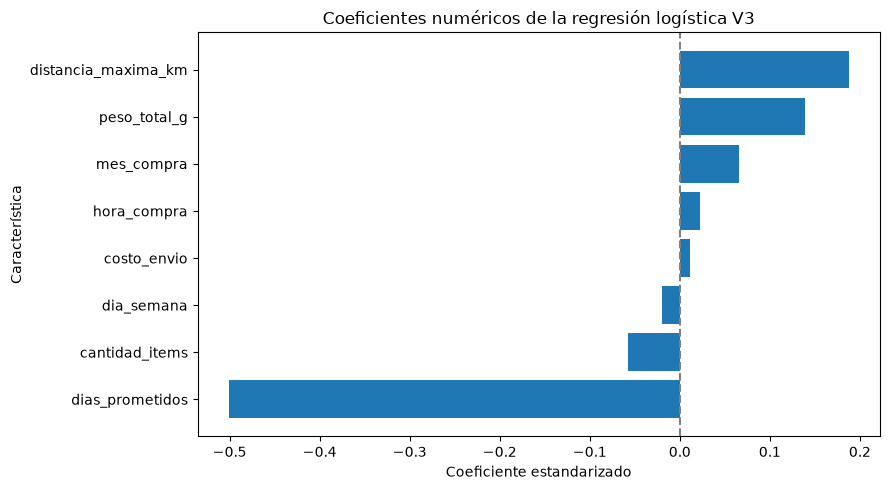

In [75]:
import matplotlib.pyplot as plt

datos_grafica = coeficientes_numericos.sort_values("Coeficiente")

plt.figure(figsize=(9, 5))

plt.barh(
    datos_grafica["Variable"].str.replace("num__", "", regex=False),
    datos_grafica["Coeficiente"]
)

plt.axvline(0, color="gray", linestyle="--")

plt.xlabel("Coeficiente estandarizado")
plt.ylabel("Característica")
plt.title("Coeficientes numéricos de la regresión logística V3")

plt.tight_layout()
plt.show()


### 16.1. Estabilidad temporal de coeficientes

In [76]:
resultados_coeficientes = []

for inicio in meses_validacion:

    historico = train_v3_fechas[
        (train_v3_fechas["order_purchase_timestamp"] < inicio)
        & (train_v3_fechas["order_delivered_customer_date"] < inicio)
    ]

    modelo = clone(modelo_logistico_v3)

    modelo.fit(
        historico[variables_v3],
        historico["retraso"]
    )

    nombres = (
        modelo.named_steps["preprocesamiento"]
        .get_feature_names_out()
    )

    valores = modelo.named_steps["clasificador"].coef_[0]

    for nombre, valor in zip(nombres, valores):
        if nombre.startswith("num__"):
            resultados_coeficientes.append({
                "Mes": inicio.strftime("%Y-%m"),
                "Variable": nombre.replace("num__", ""),
                "Coeficiente": valor
            })

tabla_coeficientes = pd.DataFrame(resultados_coeficientes)

estabilidad_coeficientes = tabla_coeficientes.pivot(
    index="Variable",
    columns="Mes",
    values="Coeficiente"
)

estabilidad_coeficientes.round(4)


Mes,2017-11,2018-02,2018-04
Variable,,,
cantidad_items,-0.0330,-0.0474,-0.0578
costo_envio,0.0651,-0.0120,0.0112
dia_semana,-0.0867,-0.0206,-0.0202
dias_prometidos,-0.6819,-0.4488,-0.5010
distancia_maxima_km,0.1520,0.1379,0.1879
hora_compra,0.0769,0.0291,0.0228
mes_compra,-0.4466,0.4764,0.0655
peso_total_g,0.1077,0.1644,0.1386


## 17. Comparación adicional: Random Forest V1 frente a V3

In [77]:
from sklearn.ensemble import RandomForestClassifier

modelo_rf_v3 = Pipeline([
    ("preprocesamiento", clone(preprocesamiento_v3)),
    ("clasificador", RandomForestClassifier(
        n_estimators=100,
        max_depth=10,
        min_samples_leaf=20,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

modelo_rf_v3


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocesamiento', ...), ('clasificador', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, defaul

In [78]:
modelo_rf = Pipeline([
    ("preprocesamiento", clone(preprocesamiento)),
    ("clasificador", RandomForestClassifier(
        n_estimators=100,
        max_depth=10,
        min_samples_leaf=20,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

modelo_rf


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocesamiento', ...), ('clasificador', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, defaul

### 17.1. Evaluación temporal de Random Forest

In [79]:
resultados_rf = []

for inicio in meses_validacion:
    fin = inicio + pd.DateOffset(months=1)

    historico = train_v3_fechas[
        (train_v3_fechas["order_purchase_timestamp"] < inicio)
        & (train_v3_fechas["order_delivered_customer_date"] < inicio)
    ]

    periodo = train_v3_fechas[
        (train_v3_fechas["order_purchase_timestamp"] >= inicio)
        & (train_v3_fechas["order_purchase_timestamp"] < fin)
    ]

    for version, modelo, columnas in [
        ("V1", modelo_rf, variables),
        ("V3", modelo_rf_v3, variables_v3)
    ]:
        estimador = clone(modelo)

        estimador.fit(
            historico[columnas],
            historico["retraso"]
        )

        probabilidades = estimador.predict_proba(
            periodo[columnas]
        )[:, 1]

        resultados_rf.append({
            "Mes": inicio.strftime("%Y-%m"),
            "Version": version,
            "AP": average_precision_score(
                periodo["retraso"],
                probabilidades
            ),
            "ROC_AUC": roc_auc_score(
                periodo["retraso"],
                probabilidades
            )
        })

tabla_rf = pd.DataFrame(resultados_rf)

tabla_rf.round(4)


,Mes,Version,AP,ROC_AUC
0,2017-11,V1,0.1151,0.4560
1,2017-11,V3,0.1135,0.4598
2,2018-02,V1,0.2190,0.6448
3,2018-02,V3,0.2593,0.6779
4,2018-04,V1,0.0737,0.6993
5,2018-04,V3,0.1295,0.7779


In [83]:
from pathlib import Path
from sklearn.base import clone
import pandas as pd
import joblib

# 1. Crear la carpeta modelos
carpeta_modelos = Path("../modelos")
carpeta_modelos.mkdir(parents=True, exist_ok=True)

# 2. Seleccionar datos históricos anteriores a abril de 2018
corte = pd.Timestamp("2018-04-01")

historico_guardado = train_v3_fechas[
    (train_v3_fechas["order_purchase_timestamp"] < corte)
    & (train_v3_fechas["order_delivered_customer_date"] < corte)
].copy()

# 3. Separar características y variable objetivo
X_guardado = historico_guardado[variables_v3]
y_guardado = historico_guardado["retraso"]

# 4. Entrenar y guardar regresión logística V3
logistica_guardada = clone(modelo_logistico_v3)
logistica_guardada.fit(X_guardado, y_guardado)

joblib.dump(
    logistica_guardada,
    carpeta_modelos / "regresion_logistica_v3.joblib"
)

# 5. Entrenar y guardar Random Forest V3
forest_guardado = clone(modelo_rf_v3)
forest_guardado.fit(X_guardado, y_guardado)

joblib.dump(
    forest_guardado,
    carpeta_modelos / "random_forest_v3.joblib"
)

# 6. Comprobar los archivos
print("Modelos guardados correctamente.")
print("Pedidos utilizados:", len(historico_guardado))

for archivo in carpeta_modelos.glob("*.joblib"):
    print(archivo.name)

Modelos guardados correctamente.
Pedidos utilizados: 60468
kmeans_rm_k3.joblib
random_forest_v3.joblib
regresion_logistica_v3.joblib


### 17.2. Comparación de algoritmos con métricas calculadas

In [80]:
comparacion_algoritmos = (
    tabla_v2_v3[tabla_v2_v3["Version"] == "V3"]
    [["Mes", "AP"]]
    .rename(columns={"AP": "Regresion_Logistica_V3"})
    .merge(
        tabla_rf[tabla_rf["Version"] == "V3"]
        [["Mes", "AP"]]
        .rename(columns={"AP": "Random_Forest_V3"}),
        on="Mes",
        validate="one_to_one"
    )
)

comparacion_algoritmos["Diferencia_AP"] = (
    comparacion_algoritmos["Regresion_Logistica_V3"]
    - comparacion_algoritmos["Random_Forest_V3"]
)

comparacion_algoritmos.round(4)


,Mes,Regresion_Logistica_V3,Random_Forest_V3,Diferencia_AP
0,2017-11,0.1659,0.1135,0.0525
1,2018-02,0.2795,0.2593,0.0202
2,2018-04,0.1379,0.1295,0.0085


### 17.3. Lift de Average Precision de V3

In [81]:
resumen_v3 = (
    tabla_v2_v3[tabla_v2_v3["Version"] == "V3"]
    [["Mes", "AP"]]
    .merge(
        tabla_temporal[["Mes", "Tasa_retraso"]].drop_duplicates(),
        on="Mes",
        validate="one_to_one"
    )
)

resumen_v3["Lift_AP"] = (
    resumen_v3["AP"] / resumen_v3["Tasa_retraso"]
)

resumen_v3.round(4)


,Mes,AP,Tasa_retraso,Lift_AP
0,2017-11,0.1659,0.1240,1.3377
1,2018-02,0.2795,0.1405,1.9899
2,2018-04,0.1379,0.0324,4.2554


## 18. Exportación de resultados

Los archivos CSV de resultados se guardan en `resultados/`, sin sobrescribir el conjunto de prueba ni los datos de las versiones.

In [82]:
from pathlib import Path

ruta_resultados = Path("../resultados")
ruta_resultados.mkdir(exist_ok=True)

resumen_v3.to_csv(
    ruta_resultados / "validacion_temporal_v3.csv",
    index=False
)

comparacion_algoritmos.to_csv(
    ruta_resultados / "comparacion_algoritmos_v3.csv",
    index=False
)

print("Archivos guardados:")
print((ruta_resultados / "validacion_temporal_v3.csv").exists())
print((ruta_resultados / "comparacion_algoritmos_v3.csv").exists())


Archivos guardados:
True
True


## 19. Conclusiones del modelado supervisado

1. Se desarrollaron y evaluaron modelos de clasificación para identificar pedidos con riesgo de retraso en sus entregas, utilizando información histórica de Olist.

2. Se construyeron tres versiones de características predictoras:
   - V1: ocho características originales.
   - V2: incorporación de los días prometidos de entrega.
   - V3: incorporación adicional de la distancia geográfica máxima entre vendedores y clientes.

3. La incorporación de nuevas características mejoró el desempeño de la regresión logística en los tres períodos de validación temporal. Los días prometidos aportaron la mejora más importante, mientras que la distancia logística produjo una mejora adicional.

4. La regresión logística V3 obtuvo una Average Precision de 0,1659 en noviembre de 2017, 0,2795 en febrero de 2018 y 0,1379 en abril de 2018. Superó a Random Forest V3 en los tres períodos evaluados.

5. La evaluación de diferentes umbrales mostró que existe un compromiso entre identificar retrasos y generar falsas alarmas. Por ello, se investigó una estrategia de priorización basada en seleccionar el 10 % de pedidos con mayor riesgo.

6. La estrategia de priorización permitió identificar el 15,82 %, 26,20 % y 45,62 % de los retrasos de noviembre, febrero y abril, respectivamente, revisando aproximadamente el 10 % de los pedidos de cada período.

7. La calibración sigmoide redujo los errores Brier Score y Log Loss frente al modelo sin calibrar. Sin embargo, no superó una referencia de probabilidad constante en abril, por lo que no se adoptó como solución definitiva.

8. El análisis de los coeficientes identificó relaciones relativamente estables entre el riesgo estimado y tres características: días prometidos, distancia máxima y peso total. Estas asociaciones no demuestran relaciones causales.

9. La regresión logística V3 se conserva como principal candidato experimental, debido a sus resultados de Average Precision y a la posibilidad de interpretar sus coeficientes.

**Limitaciones:** las evaluaciones muestran variaciones temporales importantes. Las versiones V2 y V3 se desarrollaron después de conocer el resultado de la prueba final original, por lo que requieren una evaluación independiente adicional antes de afirmar que generalizan a datos futuros. También debe verificarse que todas las características estén disponibles en el momento de realizar la predicción.

**Lectura de resultados:** el Lift de AP es una comparación con la prevalencia de retrasos, no la precisión de las alertas. Los valores obtenidos en abril con distintos modelos base o ventanas de entrenamiento no deben mezclarse como si procedieran de una misma configuración.
